# Employee Churn: End-to-End Analysis

Explore employee churn and compare four classifiers. The target is `left`:
**0 = Stayed**, **1 = Left**. This project classifies recorded churn, not
departures within a future prediction period. Associations are not causes.

Run all cells from the project folder. The first code cell installs `requirements.txt`
into the active notebook environment.
The only input file is **`data/HR_Dataset.csv`**; no separate script or split
CSVs are needed.

1. Inspect the dataset and remove exact duplicate records.
2. Create the same stratified 70/15/15 split as `split_data.py` (seed 42).
3. Explore features using training data only.
4. Tune four models using five-fold stratified training-set CV.
5. Choose the selected model's threshold using validation data.
6. Report test metrics, a confusion matrix, and ROC/precision–recall curves.

The test set has been inspected earlier in the project; it is not a fresh holdout.
Plots are saved to `plots/`, and the final summary to `results/test_metrics.csv`.
No model files or JSON metadata are written, and existing split CSVs are not overwritten.

## Install requirements
Run this cell before importing libraries. `%pip` installs packages into the current
notebook kernel's environment. Internet access may be needed. If prompted after
installation, restart the kernel and continue from the imports cell.

In [ ]:
%pip install -r requirements.txt

## 1. Imports and plot setup

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from matplotlib.ticker import PercentFormatter
from matplotlib.patches import Patch

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score,
    confusion_matrix, roc_curve, precision_recall_curve,
)

# Create the output folders.
Path('plots').mkdir(exist_ok=True)
Path('results').mkdir(exist_ok=True)

# Keep the same colors, fonts and subtle grids throughout the notebook.
sns.set_theme(style="white", context="notebook", rc={
    "figure.facecolor": "white", "axes.facecolor": "white",
    "figure.dpi": 120, "axes.axisbelow": True,
    "axes.edgecolor": "#CBD2D9", "axes.linewidth": 0.8,
    "axes.labelcolor": "#374151", "text.color": "#1F2937",
    "xtick.color": "#4B5563", "ytick.color": "#4B5563",
    "grid.color": "#E9EDF2", "grid.linewidth": 0.6,
    "axes.titleweight": "semibold", "axes.titlesize": 13,
    "axes.titlelocation": "left", "axes.titlepad": 16,
    "axes.labelsize": 11, "xtick.labelsize": 10, "ytick.labelsize": 10,
    "legend.frameon": False, "patch.linewidth": 0,
})
STATUS_ORDER = ["Stayed", "Left"]
STATUS_COLORS = {"Stayed": "#4C78A8", "Left": "#D97757"}
TOPIC_COLORS = {
    "projects": "#2A9D8F",
    "tenure": "#8172B2",
    "salary": "#B58A35",
    "department": "#607D9C",
}

def style_axes(ax, grid_axis="y"):
    ax.set_axisbelow(True)
    ax.grid(False, which="both")
    ax.grid(True, axis=grid_axis, color="#E9EDF2", linewidth=0.6)
    ax.tick_params(axis="both", length=0, pad=7)
    sns.despine(ax=ax)

## 2. Dataset overview and duplicate removal

This overview uses the full HR dataset. Check the column values, missing data,
and duplicate count before splitting. Exact duplicate rows are removed, although
employee IDs are not available to prove that identical records are the same person.

In [2]:
raw_data = pd.read_csv('data/HR_Dataset.csv')
raw_data.columns = raw_data.columns.str.strip()

print('Dataset shape:', raw_data.shape)
raw_data.info()

Dataset shape: (14999, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 10 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   satisfaction_level     14999 non-null  float64
 1   last_evaluation        14999 non-null  float64
 2   number_project         14999 non-null  int64  
 3   average_montly_hours   14999 non-null  int64  
 4   time_spend_company     14999 non-null  int64  
 5   Work_accident          14999 non-null  int64  
 6   left                   14999 non-null  int64  
 7   promotion_last_5years  14999 non-null  int64  
 8   Departments            14999 non-null  object 
 9   salary                 14999 non-null  object 
dtypes: float64(2), int64(6), object(2)
memory usage: 1.1+ MB


### Column types and observed values (full dataset overview)
Unique categories, observed numeric ranges and 0/1 meanings from `HR_Dataset.csv`.

In [3]:
# Describe each column using the values observed in the full dataset.
binary_meanings = {
    'Work_accident': '0 = No recorded accident; 1 = Recorded accident',
    'left': '0 = Stayed; 1 = Left',
    'promotion_last_5years': '0 = Not promoted; 1 = Promoted',
}
column_rows = []
for column in raw_data.columns:
    values = raw_data[column]
    if column in binary_meanings:
        column_type = 'Binary'
        description = '0, 1 (' + binary_meanings[column] + ')'
    elif values.dtype == 'object':
        column_type = 'Categorical'
        description = ', '.join(sorted(values.dropna().unique()))
    else:
        column_type = 'Numeric'
        description = f'{values.min():g} – {values.max():g}'

    column_rows.append({
        'Column': column,
        'Type': column_type,
        'Data type': str(values.dtype),
        'Values / range': description,
        'Missing values': values.isna().sum(),
    })

column_values = pd.DataFrame(column_rows)
# Formatting only: left-align text and wrap long category lists.
display(
    column_values.style.hide(axis='index')
    .set_properties(**{'text-align': 'left', 'vertical-align': 'top'})
    .set_properties(subset=['Values / range'], **{
        'white-space': 'normal', 'overflow-wrap': 'anywhere', 'max-width': '700px',
    })
)

Column,Type,Data type,Values / range,Missing values
satisfaction_level,Numeric,float64,0.09 – 1,0
last_evaluation,Numeric,float64,0.36 – 1,0
number_project,Numeric,int64,2 – 7,0
average_montly_hours,Numeric,int64,96 – 310,0
time_spend_company,Numeric,int64,2 – 10,0
Work_accident,Binary,int64,"0, 1 (0 = No recorded accident; 1 = Recorded accident)",0
left,Binary,int64,"0, 1 (0 = Stayed; 1 = Left)",0
promotion_last_5years,Binary,int64,"0, 1 (0 = Not promoted; 1 = Promoted)",0
Departments,Categorical,object,"IT, RandD, accounting, hr, management, marketing, product_mng, sales, support, technical",0
salary,Categorical,object,"high, low, medium",0


In [4]:
clean_data = raw_data.drop_duplicates().reset_index(drop=True)
clean_data["Status"] = clean_data["left"].map({0: "Stayed", 1: "Left"})
clean_churn_rate = clean_data["left"].mean() * 100
status_counts = clean_data["Status"].value_counts().reindex(STATUS_ORDER)

overview = pd.DataFrame({
    "Dataset": ["Before duplicate removal", "After duplicate removal (analysis)"],
    "Employees (n)": [len(raw_data), len(clean_data)],
    "Employees who left": [int(raw_data["left"].sum()), int(clean_data["left"].sum())],
    "Churn rate (%)": [raw_data["left"].mean() * 100, clean_churn_rate],
})
display(overview.style.format({"Churn rate (%)": "{:.2f}"}).hide(axis="index"))
print(f"Exact duplicate rows removed: {raw_data.duplicated().sum():,}")
display(raw_data.isna().sum().rename("Missing values").to_frame())

status_summary = status_counts.rename("Employees (n)").to_frame()
status_summary["Share (%)"] = status_summary["Employees (n)"] / len(clean_data) * 100
display(status_summary.style.format({"Share (%)": "{:.2f}"}))

Dataset,Employees (n),Employees who left,Churn rate (%)
Before duplicate removal,14999,3571,23.81
After duplicate removal (analysis),11991,1991,16.60


Exact duplicate rows removed: 3,008


,Missing values
satisfaction_level,0
last_evaluation,0
number_project,0
average_montly_hours,0
time_spend_company,0
Work_accident,0
left,0
promotion_last_5years,0
Departments,0
salary,0


,Employees (n),Share (%)
Status,,
Stayed,10000,83.40
Left,1991,16.60


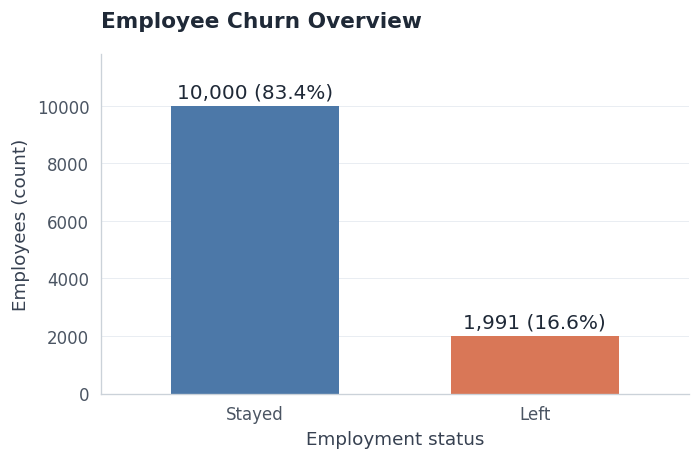

In [5]:
ax = status_counts.plot.bar(color=[STATUS_COLORS[status] for status in STATUS_ORDER], rot=0, width=0.6, edgecolor="none", figsize=(6, 4))
style_axes(ax)
for bar, count in zip(ax.patches, status_counts):
    ax.annotate(f"{count:,} ({count / len(clean_data):.1%})", (bar.get_x() + bar.get_width() / 2, bar.get_height()), xytext=(0, 5), textcoords="offset points", ha="center")
ax.set(title="Employee Churn Overview", xlabel="Employment status", ylabel="Employees (count)")
ax.set_ylim(0, status_counts.max() * 1.18)
plt.tight_layout()
plt.savefig('plots/01_churn_overview.png', dpi=300)
plt.show()

In [6]:
display(clean_data.head())
display(clean_data.describe(include='all'))

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Departments,salary,Status
0,0.38,0.53,2,157,3,0,1,0,sales,low,Left
1,0.80,0.86,5,262,6,0,1,0,sales,medium,Left
2,0.11,0.88,7,272,4,0,1,0,sales,medium,Left
3,0.72,0.87,5,223,5,0,1,0,sales,low,Left
4,0.37,0.52,2,159,3,0,1,0,sales,low,Left


,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years,Departments,salary,Status
count,11991.000000,11991.000000,11991.000000,11991.000000,11991.000000,11991.000000,11991.000000,11991.000000,11991,11991,11991
unique,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,10,3,2
top,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,sales,low,Stayed
freq,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3239,5740,10000
mean,0.629658,0.716683,3.802852,200.473522,3.364857,0.154282,0.166041,0.016929,NaN,NaN,NaN
std,0.241070,0.168343,1.163238,48.727813,1.330240,0.361234,0.372133,0.129012,NaN,NaN,NaN
min,0.090000,0.360000,2.000000,96.000000,2.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN
25%,0.480000,0.570000,3.000000,157.000000,3.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN
50%,0.660000,0.720000,4.000000,200.000000,3.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN
75%,0.820000,0.860000,5.000000,243.000000,4.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN


**Interpretation.** Stayers outnumber leavers about 5:1 (83.4% vs. 16.6%). A model that always predicts *Stayed* gets about 83% accuracy but finds no leavers, so we select models by Left-class F1 and use stratified splits.

## 3. Create the training, validation, and test splits

Use the same two stratified splits as `split_data.py`: 70% training, 15%
validation, and 15% test, with seed 42. Stratification keeps similar churn rates.
Keep these DataFrames in memory instead of writing and reloading split CSVs.
The `Status` column is an EDA label derived from the target, not an input feature.

In [7]:
# Remove the display-only Status label before splitting.
split_data = clean_data.drop(columns='Status')

train_split, remaining = train_test_split(
    split_data, test_size=0.30, stratify=split_data['left'], random_state=42,
)
val_split, test_split = train_test_split(
    remaining, test_size=0.50, stratify=remaining['left'], random_state=42,
)

data_summary = pd.DataFrame({
    'Split': ['Train', 'Validation', 'Test'],
    'Rows': [len(train_split), len(val_split), len(test_split)],
    'Missing values': [train_split.isna().sum().sum(), val_split.isna().sum().sum(),
                       test_split.isna().sum().sum()],
    'Churn rate': [train_split['left'].mean(), val_split['left'].mean(), test_split['left'].mean()],
})
display(data_summary.round(4))

,Split,Rows,Missing values,Churn rate
0,Train,8393,0,0.1661
1,Validation,1799,0,0.1662
2,Test,1799,0,0.1656


## 4. Training-set exploratory analysis

Only the training split is used below. Work on a copy so the display-only
`Status` column never becomes a model input. All flagged outliers are retained.

In [8]:
# All feature analysis below uses this training split only.
train = train_split.copy()
train.columns = train.columns.str.strip()
train["Status"] = train["left"].map({0: "Stayed", 1: "Left"})
training_rate = train["left"].mean() * 100
status_counts = train["Status"].value_counts().reindex(STATUS_ORDER, fill_value=0)
print(f"Analysis dataset: training split | Employees: {len(train):,} | Churn rate: {training_rate:.2f}%")
training_summary = status_counts.rename("Employees (n)").to_frame()
training_summary["Share (%)"] = training_summary["Employees (n)"] / len(train) * 100
display(training_summary.style.format({"Share (%)": "{:.2f}"}))

Analysis dataset: training split | Employees: 8,393 | Churn rate: 16.61%


,Employees (n),Share (%)
Status,,
Stayed,6999,83.39
Left,1394,16.61


### 4.1. Univariate analysis and outliers
Compare the distributions of the five numerical features using training data only. Each box shows the middle 50% of values and the median. Whiskers extend to the most extreme values within 1.5 times the interquartile range (IQR); points beyond them are flagged, not automatically removed. Each feature has its own vertical scale.

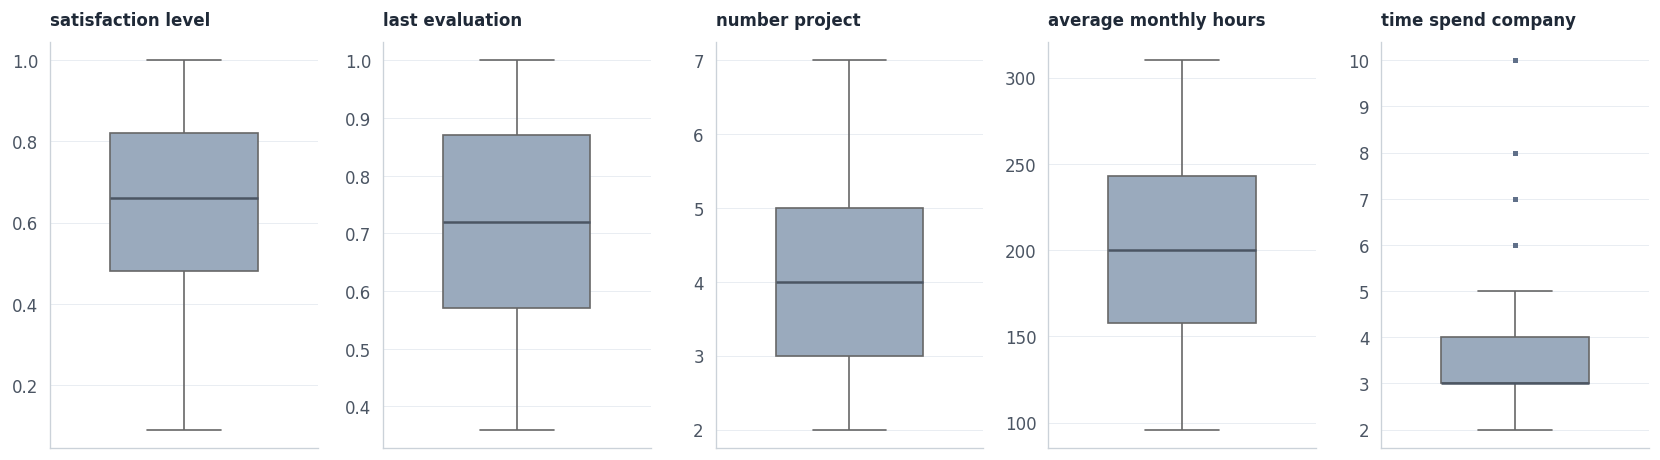

In [9]:
numeric_features = [
    'satisfaction_level', 'last_evaluation', 'number_project',
    'average_montly_hours', 'time_spend_company',
]
feature_titles = [
    'satisfaction level', 'last evaluation', 'number project',
    'average monthly hours', 'time spend company',
]

fig, axes = plt.subplots(1, 5, figsize=(14, 4))
for ax, column, title in zip(axes, numeric_features, feature_titles):
    sns.boxplot(
        data=train, y=column, ax=ax, color='#9AAABD', saturation=1,
        width=0.55, whis=1.5, linewidth=1,
        medianprops={'color': '#4B5563', 'linewidth': 1.5},
        flierprops={'marker': 'o', 'markersize': 3,
                    'markerfacecolor': '#607089', 'markeredgecolor': 'none'},
    )
    ax.set_title(title, fontsize=10, pad=10)
    ax.set_xlabel('')
    ax.set_ylabel('')
    ax.set_xticks([])
    style_axes(ax)

fig.tight_layout()
fig.savefig('plots/07_numeric_boxplots.png', dpi=300)
plt.show()

In [10]:
# Count values outside the 1.5 x IQR fences. Do not remove any rows.
outlier_rows = []
for column in numeric_features:
    q1 = train[column].quantile(0.25)
    q3 = train[column].quantile(0.75)
    iqr = q3 - q1
    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    flagged = (train[column] < lower_fence) | (train[column] > upper_fence)
    outlier_rows.append({
        'Feature': column,
        'Training rows': len(train),
        'Lower fence': lower_fence,
        'Upper fence': upper_fence,
        'Flagged rows': flagged.sum(),
        'Flagged (%)': flagged.mean() * 100,
    })

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary.round(2))

,Feature,Training rows,Lower fence,Upper fence,Flagged rows,Flagged (%)
0,satisfaction_level,8393,-0.03,1.33,0,0.00
1,last_evaluation,8393,0.12,1.32,0,0.00
2,number_project,8393,0.00,8.00,0,0.00
3,average_montly_hours,8393,30.50,370.50,0,0.00
4,time_spend_company,8393,1.50,5.50,590,7.03


**Interpretation.** Only tenure has outliers under the 1.5 × IQR rule: 590 rows (7.0%) at 6, 7, 8, or 10 years. These are recorded, plausible values, so we keep them; an outlier flag alone does not establish a data error. No training records with 7+ years are labeled Left (see Section 4.4, Tenure and promotion).

### 4.2. Satisfaction and evaluation
Compare satisfaction and evaluation scores between employees who stayed and left. Each group's histogram sums to 100%; bar heights show the share within that group, not churn rates.

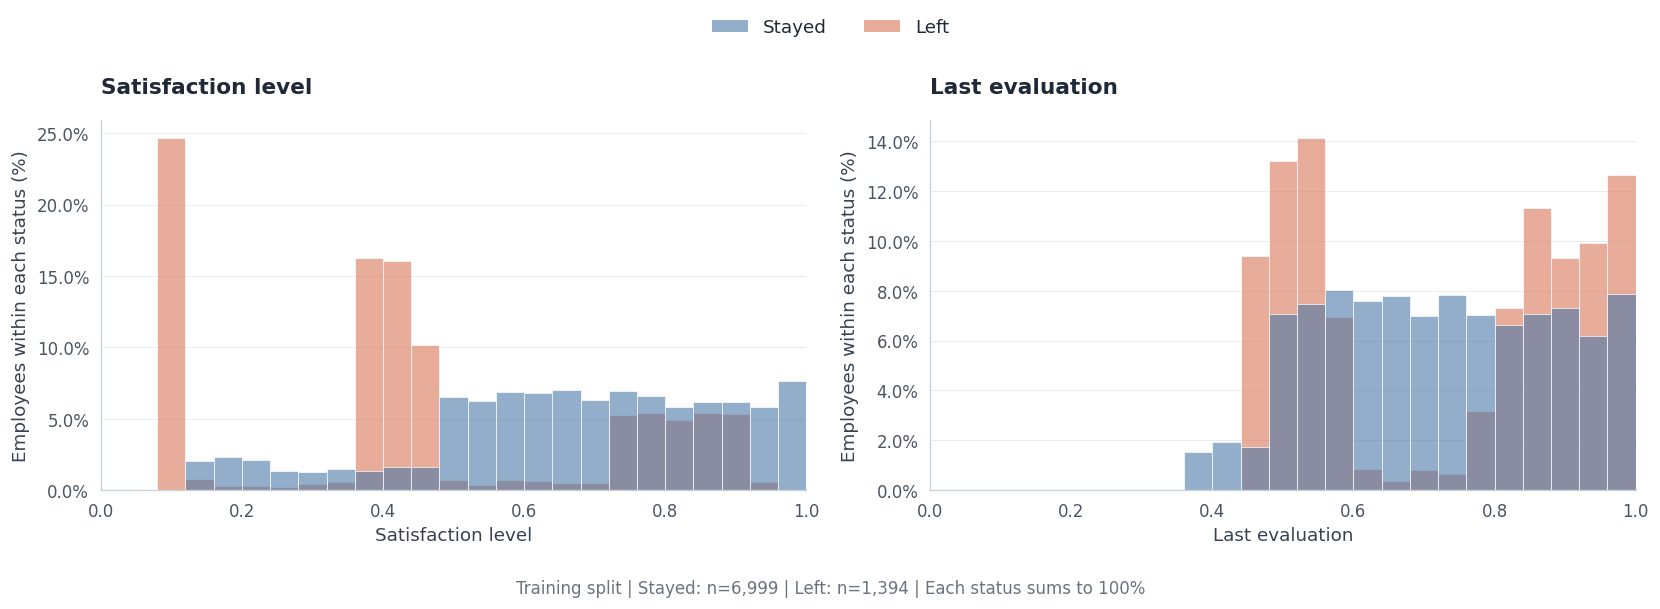

In [11]:
score_columns = {"satisfaction_level": "Satisfaction level", "last_evaluation": "Last evaluation"}
score_bins = np.linspace(0, 1, 26)  # 25 common bins for both statuses
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True)
for ax, (column, label) in zip(axes, score_columns.items()):
    sns.histplot(data=train, x=column, hue="Status", hue_order=STATUS_ORDER,
                 bins=score_bins, stat="percent", common_norm=False,
                 multiple="layer", palette=STATUS_COLORS, alpha=0.6,
                 edgecolor="white", linewidth=0.4, legend=False, ax=ax)
    style_axes(ax)
    ax.set(title=label, xlabel=label, ylabel="Employees within each status (%)", xlim=(0, 1))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
legend_handles = []
for status in STATUS_ORDER:
    legend_handles.append(Patch(facecolor=STATUS_COLORS[status], label=status, alpha=0.6))
fig.legend(handles=legend_handles,
           loc="upper center", bbox_to_anchor=(0.5, 1.0), ncol=2)
fig.text(0.5, 0.015, f"Training split | Stayed: n={status_counts['Stayed']:,} | Left: n={status_counts['Left']:,} | Each status sums to 100%",
         ha="center", fontsize=10, color="#6B7280")
fig.tight_layout(rect=(0, 0.06, 1, 0.91))
fig.savefig('plots/02_satisfaction_evaluation.png', dpi=300)
plt.show()

In [12]:
display(train.groupby("Status")[list(score_columns)].agg(["count", "mean", "median"]).reindex(STATUS_ORDER).round(3))

satisfaction_level               last_evaluation              
                    count   mean median           count   mean median
Status                                                               
Stayed               6999  0.666   0.69            6999  0.716   0.71
Left                 1394  0.444   0.41            1394  0.723   0.80

**Interpretation.** Leavers are not one group. Their satisfaction has three clusters (≈ 26% below 0.2, ≈ 44% in [0.3,0.5), ≈ 27% at least 0.7), so low satisfaction does not characterize all churn. Evaluation has almost the same mean for both groups (0.723 vs. 0.716), but leavers are split into low scores (43.7% below 0.6) and high scores (50.5% at least 0.8). Only 5.8% are in the middle [0.6,0.8) (stayers: 37.2%). Means and linear correlation can miss these patterns, motivating non-linear models.

### 4.3. Workload
Compare churn rates by number of projects and monthly working hours between employees who stayed and left. The dashed line marks the training-set churn rate; tables show group sizes and median hours.

In [13]:
# A small helper avoids repeating the same group calculation in each section.
def churn_summary(column):
    summary = train.groupby(column, observed=True)['left'].agg(['size', 'sum', 'mean'])
    summary.columns = ['Total employees', 'Employees who left', 'Churn rate (%)']
    summary['Churn rate (%)'] = summary['Churn rate (%)'] * 100
    return summary

project_summary = churn_summary('number_project')
display(project_summary.style.format({'Churn rate (%)': '{:.2f}'}))

hours_summary = train.groupby('Status')['average_montly_hours'].agg(['size', 'median'])
hours_summary.columns = ['Total employees', 'Median monthly hours']
hours_summary = hours_summary.reindex(STATUS_ORDER)
hours_summary.index.name = 'Employment status'
display(hours_summary.style.format({'Total employees': '{:,.0f}', 'Median monthly hours': '{:.0f}'}))

,Total employees,Employees who left,Churn rate (%)
number_project,,,
2,1102,599,54.36
3,2468,28,1.13
4,2563,163,6.36
5,1566,246,15.71
6,594,258,43.43
7,100,100,100.00


,Total employees,Median monthly hours
Employment status,,
Stayed,"6,999",198
Left,"1,394",226


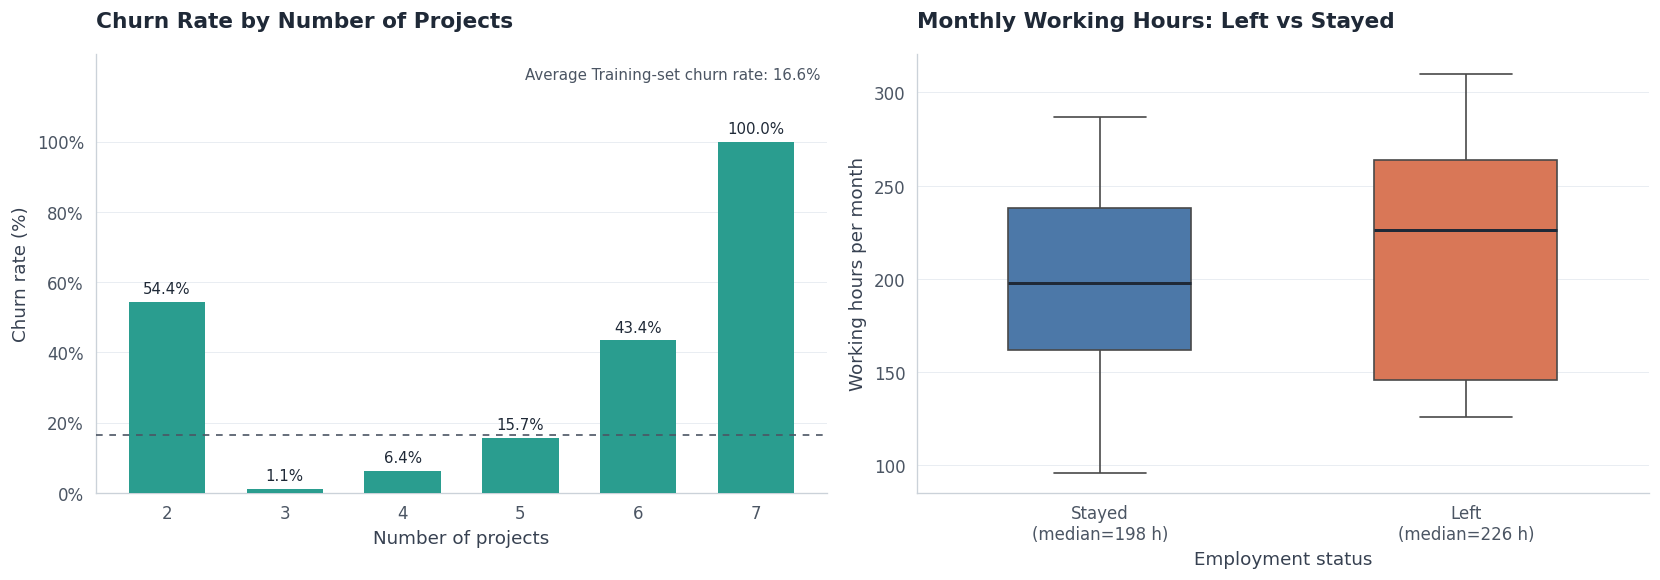

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].bar(project_summary.index.astype(str), project_summary['Churn rate (%)'],
          color=TOPIC_COLORS['projects'], width=0.65, edgecolor='none', zorder=3)
axes[0].axhline(training_rate, color='#4B5563', linestyle=(0, (4, 4)), linewidth=1, zorder=4)
axes[0].text(0.99, 0.97, f'Average Training-set churn rate: {training_rate:.1f}%',
           transform=axes[0].transAxes, ha='right', va='top', fontsize=9, color='#4B5563')
rate_limit = max(30, project_summary['Churn rate (%)'].max() * 1.25, training_rate * 1.25)
axes[0].set(title='Churn Rate by Number of Projects', xlabel='Number of projects', ylabel='Churn rate (%)', ylim=(0, rate_limit))
axes[0].set_yticks(np.arange(0, min(rate_limit, 100) + 0.01, 20))
axes[0].yaxis.set_major_formatter(PercentFormatter(xmax=100))
for position, rate in enumerate(project_summary['Churn rate (%)']):
    axes[0].annotate(f'{rate:.1f}%', (position, rate), xytext=(0, 5),
                   textcoords='offset points', ha='center', fontsize=9)
style_axes(axes[0])
sns.boxplot(data=train, x="Status", y="average_montly_hours", order=STATUS_ORDER,
            hue="Status", hue_order=STATUS_ORDER, palette=STATUS_COLORS, dodge=False,
            width=0.5, linewidth=1, saturation=1,
            medianprops={"color": "#1F2937", "linewidth": 1.8},
            flierprops={"marker": "o", "markersize": 3, "alpha": 0.3}, ax=axes[1])
style_axes(axes[1])
hour_medians = train.groupby("Status")["average_montly_hours"].median()
axes[1].set_xticks(range(2), [f"{status}\n(median={hour_medians[status]:.0f} h)" for status in STATUS_ORDER])
axes[1].set(title="Monthly Working Hours: Left vs Stayed", xlabel="Employment status", ylabel="Working hours per month")
plt.tight_layout()
fig.savefig('plots/03_workload.png', dpi=300)
plt.show()

**Interpretation.** Both low and high workload are associated with more churn. Churn is 54.4% at 2 projects, 1.1–6.4% at 3–4, 43.4% at 6 and 100% at 7 (n=100). Hours agree: 36.7% of leavers work at least 250 h (stayers: 17.8%) and 30.3% at most 150 h (stayers: 16.8%). The implemented Logistic Regression has no non-linear terms to directly fit this U-shape, which may partly explain its weaker result.

### 4.4. Tenure and promotion
Compare churn rates by years at the company and promotion in the last five years. Tables show group sizes and the number who left.

In [15]:
tenure_summary = churn_summary('time_spend_company')
display(tenure_summary.style.format({'Churn rate (%)': '{:.2f}'}))

promotion_summary = churn_summary('promotion_last_5years')
promotion_summary = promotion_summary.rename(index={0: 'Not promoted', 1: 'Promoted'})
promotion_summary.index.name = 'Promotion in the last five years'
display(promotion_summary.style.format({'Churn rate (%)': '{:.2f}'}))

,Total employees,Employees who left,Churn rate (%)
time_spend_company,,,
2,2020,21,1.04
3,3639,608,16.71
4,1404,341,24.29
5,740,337,45.54
6,400,87,21.75
7,64,0,0.00
8,56,0,0.00
10,70,0,0.00


,Total employees,Employees who left,Churn rate (%)
Promotion in the last five years,,,
Not promoted,8257,1387,16.80
Promoted,136,7,5.15


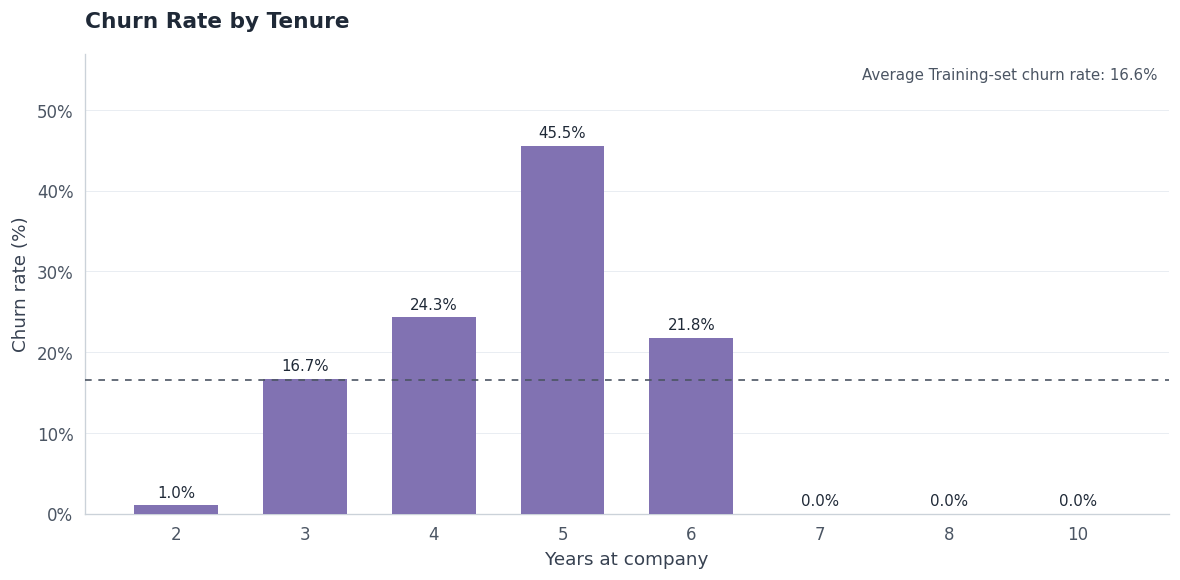

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(tenure_summary.index.astype(str), tenure_summary['Churn rate (%)'],
          color=TOPIC_COLORS['tenure'], width=0.65, edgecolor='none', zorder=3)
ax.axhline(training_rate, color='#4B5563', linestyle=(0, (4, 4)), linewidth=1, zorder=4)
ax.text(0.99, 0.97, f'Average Training-set churn rate: {training_rate:.1f}%',
           transform=ax.transAxes, ha='right', va='top', fontsize=9, color='#4B5563')
rate_limit = max(30, tenure_summary['Churn rate (%)'].max() * 1.25, training_rate * 1.25)
ax.set(title='Churn Rate by Tenure', xlabel='Years at company', ylabel='Churn rate (%)', ylim=(0, rate_limit))
ax.set_yticks(np.arange(0, min(rate_limit, 100) + 0.01, 10))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100))
for position, rate in enumerate(tenure_summary['Churn rate (%)']):
    ax.annotate(f'{rate:.1f}%', (position, rate), xytext=(0, 5),
                   textcoords='offset points', ha='center', fontsize=9)
style_axes(ax)
plt.tight_layout()
fig.savefig('plots/04_tenure.png', dpi=300)
plt.show()

**Interpretation.** Churn is concentrated in years 3–6 and peaks at 45.5% in year 5; year 2 also has 1.0% churn. No training records with 7+ years are labeled Left (n=190). Promoted employees have lower churn (5.1% vs. 16.8%), but only 7 of 136 left, so this small-group association should be interpreted cautiously.

### 4.5. Salary, department and work accidents
Compare churn rates across salary levels, departments and recorded work-accident groups. Departments are ranked by churn rate; tables show group sizes and the number who left.

In [17]:
salary_summary = churn_summary('salary').reindex(['low', 'medium', 'high'])
department_summary = churn_summary('Departments').sort_values('Churn rate (%)', ascending=False)
display(salary_summary.style.format({'Churn rate (%)': '{:.2f}'}))
display(department_summary.style.format({'Churn rate (%)': '{:.2f}'}))

accident_summary = churn_summary('Work_accident')
accident_summary = accident_summary.rename(index={0: 'No recorded accident', 1: 'Recorded accident'})
accident_summary.index.name = 'Recorded work accident'
display(accident_summary.style.format({'Churn rate (%)': '{:.2f}'}))

,Total employees,Employees who left,Churn rate (%)
salary,,,
low,4028,823,20.43
medium,3662,542,14.80
high,703,29,4.13


,Total employees,Employees who left,Churn rate (%)
Departments,,,
hr,421,79,18.76
accounting,437,79,18.08
sales,2249,401,17.83
marketing,476,83,17.44
technical,1583,271,17.12
IT,682,116,17.01
support,1284,203,15.81
product_mng,491,75,15.27
RandD,486,56,11.52


,Total employees,Employees who left,Churn rate (%)
Recorded work accident,,,
No recorded accident,7091,1320,18.62
Recorded accident,1302,74,5.68


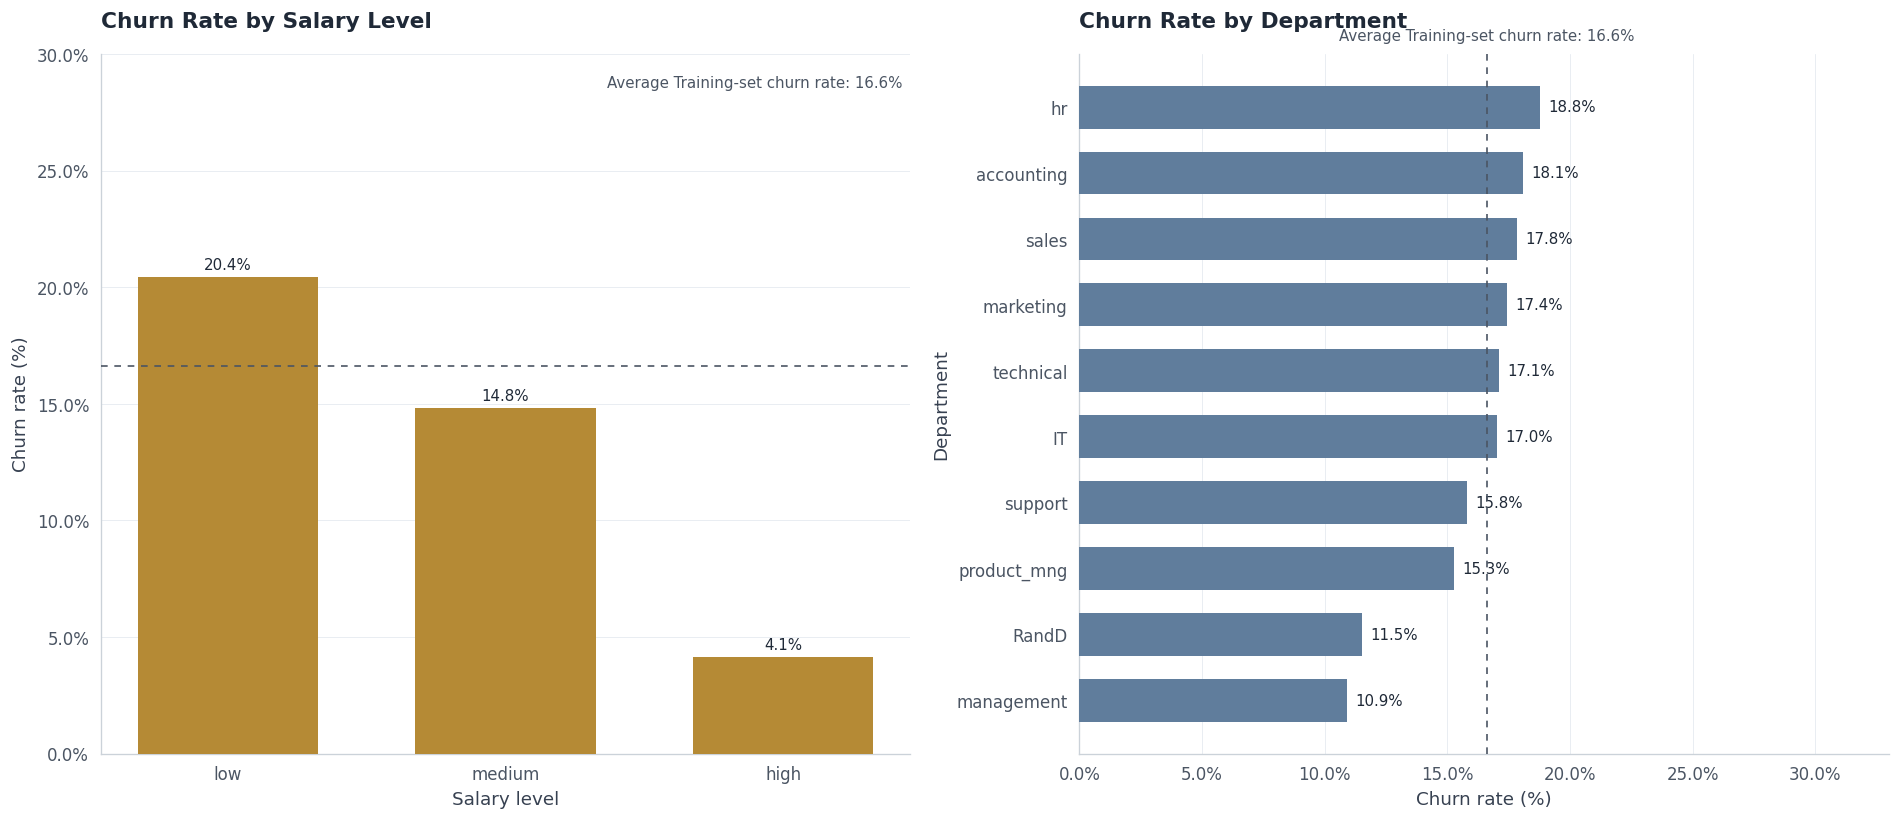

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].bar(salary_summary.index.astype(str), salary_summary['Churn rate (%)'],
          color=TOPIC_COLORS['salary'], width=0.65, edgecolor='none', zorder=3)
axes[0].axhline(training_rate, color='#4B5563', linestyle=(0, (4, 4)), linewidth=1, zorder=4)
axes[0].text(0.99, 0.97, f'Average Training-set churn rate: {training_rate:.1f}%',
           transform=axes[0].transAxes, ha='right', va='top', fontsize=9, color='#4B5563')
rate_limit = max(30, salary_summary['Churn rate (%)'].max() * 1.25, training_rate * 1.25)
axes[0].set(title='Churn Rate by Salary Level', xlabel='Salary level', ylabel='Churn rate (%)', ylim=(0, rate_limit))
axes[0].set_yticks(np.arange(0, min(rate_limit, 100) + 0.01, 5))
axes[0].yaxis.set_major_formatter(PercentFormatter(xmax=100))
for position, rate in enumerate(salary_summary['Churn rate (%)']):
    axes[0].annotate(f'{rate:.1f}%', (position, rate), xytext=(0, 5),
                   textcoords='offset points', ha='center', fontsize=9)
style_axes(axes[0])

# Departments use horizontal bars so their names are easy to read.
axes[1].barh(department_summary.index, department_summary['Churn rate (%)'],
             color=TOPIC_COLORS['department'], height=0.65, edgecolor='none', zorder=3)
axes[1].invert_yaxis()
axes[1].axvline(training_rate, color='#4B5563', linestyle=(0, (4, 4)), linewidth=1, zorder=4)
axes[1].text(training_rate, 1.015, f'Average Training-set churn rate: {training_rate:.1f}%',
             transform=axes[1].get_xaxis_transform(), ha='center', va='bottom',
             fontsize=9, color='#4B5563', clip_on=False)
rate_limit = max(30, department_summary['Churn rate (%)'].max() * 1.25, training_rate * 1.25)
axes[1].set(title='Churn Rate by Department', xlabel='Churn rate (%)',
            ylabel='Department', xlim=(0, rate_limit * 1.1))
axes[1].set_xticks(np.arange(0, min(rate_limit, 100) + 0.01, 5))
axes[1].xaxis.set_major_formatter(PercentFormatter(xmax=100))
for position, rate in enumerate(department_summary['Churn rate (%)']):
    axes[1].annotate(f'{rate:.1f}%', (rate, position), xytext=(5, 0),
                     textcoords='offset points', va='center', fontsize=9)
style_axes(axes[1], grid_axis='x')
plt.tight_layout()
fig.savefig('plots/05_salary_department.png', dpi=300)
plt.show()

**Interpretation.** Churn falls as salary rises (20.4%, 14.8%, 4.1%). Departments differ little (mostly 15–19%). Recorded work accidents are associated with lower churn (5.7% vs. 18.6%), but this does not show that an accident protects against leaving. This is another reason not to read these rates as causes.

### 4.6. Correlation analysis
Compute the Pearson correlation matrix for numeric and binary features using the training split.

In [19]:
corr_columns = [
    'satisfaction_level', 'last_evaluation', 'number_project',
    'average_montly_hours', 'time_spend_company', 'Work_accident',
    'left', 'promotion_last_5years',
]
corr_matrix = train[corr_columns].corr()
display(corr_matrix.round(2))

,satisfaction_level,last_evaluation,number_project,average_montly_hours,time_spend_company,Work_accident,left,promotion_last_5years
satisfaction_level,1.00,0.10,-0.13,-0.01,-0.15,0.04,-0.34,0.02
last_evaluation,0.10,1.00,0.26,0.26,0.10,-0.00,0.02,-0.01
number_project,-0.13,0.26,1.00,0.32,0.20,-0.00,0.03,0.01
average_montly_hours,-0.01,0.26,0.32,1.00,0.11,-0.01,0.07,0.00
time_spend_company,-0.15,0.10,0.20,0.11,1.00,-0.00,0.18,0.05
Work_accident,0.04,-0.00,-0.00,-0.01,-0.00,1.00,-0.13,0.03
left,-0.34,0.02,0.03,0.07,0.18,-0.13,1.00,-0.04
promotion_last_5years,0.02,-0.01,0.01,0.00,0.05,0.03,-0.04,1.00


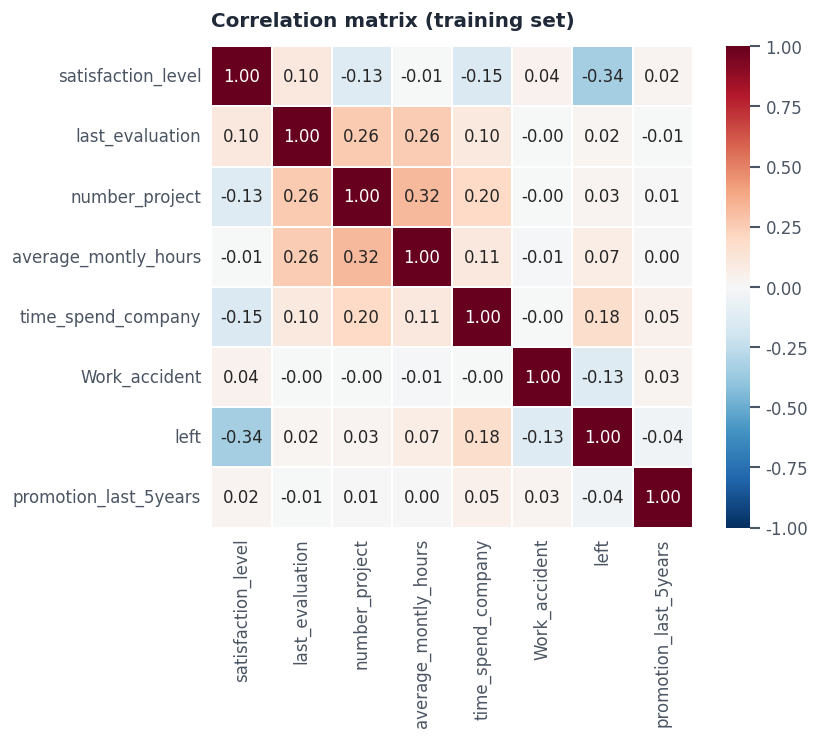

In [20]:
fig, ax = plt.subplots(figsize=(7.5, 6.2))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='RdBu_r',
    vmin=-1,
    vmax=1,
    linewidths=1,
    linecolor='white',
    cbar_kws={'ticks': np.arange(-1.0, 1.01, 0.25), 'format': '%.2f'},
    ax=ax,
    square=True,
    annot_kws={'size': 10},
)
ax.tick_params(axis='both', length=0, pad=6)
ax.set_title('Correlation matrix (training set)', fontweight='bold', fontsize=12, pad=12)
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
fig.savefig('plots/06_correlation_matrix.png', dpi=300)
plt.show()

**Interpretation.** Linear correlations with `left` are limited: -0.343 for satisfaction, +0.179 for tenure, -0.126 for work accident, and |r| < 0.08 for the other numeric/binary inputs. Yet evaluation, projects and hours show non-linear patterns, so a linear-correlation filter could discard useful inputs. This supports retaining all nine features rather than filtering by correlation alone. Pairwise correlations among the numeric/binary inputs are modest (largest 0.324); this does not assess the encoded categorical inputs.

### EDA takeaway for classification
- Satisfaction, workload extremes, and mid-tenure distinguish leavers from stayers.
- Evaluation and workload show non-linear patterns that simple averages or linear correlations can obscure.
- Some subgroups have nearly deterministic outcomes, helping explain high classification scores within this dataset.

## 5. Prepare features for classification

Use fresh copies of the original splits, without the EDA-only `Status` label.
Normalize column names for the model pipelines. `X` contains the nine inputs
and `y` contains the churn label. CV uses training rows only; validation chooses
the threshold; test scores do not choose the model or its settings.

In [21]:
train = train_split.copy()
val = val_split.copy()
test = test_split.copy()

for data in [train, val, test]:
    data.columns = data.columns.str.lower().str.strip()

# Use the original classification plot style for the remaining figures.
plt.rcdefaults()

In [22]:
X_train = train.drop(columns='left')
y_train = train['left']

X_val = val.drop(columns='left')
y_val = val['left']

X_test = test.drop(columns='left')
y_test = test['left']

## 6. Define preprocessing
- Encode salary as low = 0, medium = 1, high = 2.
- One-hot encode departments.
- Scale numerical features for logistic regression and KNN, but not for trees.
- Keep binary features as 0/1.

Preprocessing stays **inside each pipeline**, so CV fits it on each training fold only.

In [23]:
numeric_columns = [
    'satisfaction_level', 'last_evaluation', 'number_project',
    'average_montly_hours', 'time_spend_company',
]
binary_columns = ['work_accident', 'promotion_last_5years']

scaled_preprocessor = ColumnTransformer([
    ('salary', OrdinalEncoder(categories=[['low', 'medium', 'high']],
                              handle_unknown='use_encoded_value', unknown_value=-1), ['salary']),
    ('department', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['departments']),
    ('numeric', StandardScaler(), numeric_columns),
    ('binary', 'passthrough', binary_columns),
])

tree_preprocessor = ColumnTransformer([
    ('salary', OrdinalEncoder(categories=[['low', 'medium', 'high']],
                              handle_unknown='use_encoded_value', unknown_value=-1), ['salary']),
    ('department', OneHotEncoder(handle_unknown='ignore', sparse_output=False), ['departments']),
    ('numeric', 'passthrough', numeric_columns),
    ('binary', 'passthrough', binary_columns),
])

## 7. Tune the models
Use the same five stratified folds for every model. Stratification keeps similar churn
rates in each fold. Seed 42 makes the folds and stochastic models reproducible.

`scoring='f1'` chooses parameters using churn-class F1. `GridSearchCV` then fits
the best configuration on all training rows automatically. Two workers limit CPU usage.

In [24]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

### Logistic regression
A simple linear baseline. `C` controls regularization; balanced class weights give
more weight to the minority class.

In [25]:
lr_pipeline = Pipeline([
    ('preprocessor', scaled_preprocessor),
    ('model', LogisticRegression(max_iter=2000, random_state=42)),
])
lr_grid = {
    'model__C': [0.1, 1, 10],
    'model__class_weight': [None, 'balanced'],
}

lr_search = GridSearchCV(lr_pipeline, lr_grid, scoring='f1', cv=cv,
                         n_jobs=2, pre_dispatch=2, error_score='raise')
lr_search.fit(X_train, y_train)
print('Best parameters:', lr_search.best_params_)
print('Mean CV F1:', round(lr_search.best_score_, 4))

Best parameters: {'model__C': 1, 'model__class_weight': 'balanced'}
Mean CV F1: 0.5456


### K-nearest neighbors
Try different numbers of neighbors and either equal or distance-based voting.

In [26]:
knn_pipeline = Pipeline([
    ('preprocessor', scaled_preprocessor),
    ('model', KNeighborsClassifier()),
])
knn_grid = {
    'model__n_neighbors': [3, 5, 7, 9],
    'model__weights': ['uniform', 'distance'],
}

knn_search = GridSearchCV(knn_pipeline, knn_grid, scoring='f1', cv=cv,
                          n_jobs=2, pre_dispatch=2, error_score='raise')
knn_search.fit(X_train, y_train)
print('Best parameters:', knn_search.best_params_)
print('Mean CV F1:', round(knn_search.best_score_, 4))

Best parameters: {'model__n_neighbors': 3, 'model__weights': 'uniform'}
Mean CV F1: 0.8712


### Random Forest
Tune the number of trees, maximum depth, and minimum samples needed to split a node.

In [27]:
rf_pipeline = Pipeline([
    ('preprocessor', tree_preprocessor),
    ('model', RandomForestClassifier(random_state=42, n_jobs=1)),
])
rf_grid = {
    'model__n_estimators': [100, 200],
    'model__max_depth': [10, 20, None],
    'model__min_samples_split': [2, 5],
}

rf_search = GridSearchCV(rf_pipeline, rf_grid, scoring='f1', cv=cv,
                         n_jobs=2, pre_dispatch=2, error_score='raise')
rf_search.fit(X_train, y_train)
print('Best parameters:', rf_search.best_params_)
print('Mean CV F1:', round(rf_search.best_score_, 4))

Best parameters: {'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 100}
Mean CV F1: 0.9451


### Gradient Boosting
Tune the number of trees, learning rate, and tree depth.

In [28]:
gb_pipeline = Pipeline([
    ('preprocessor', tree_preprocessor),
    ('model', GradientBoostingClassifier(random_state=42)),
])
gb_grid = {
    'model__n_estimators': [100, 150],
    'model__learning_rate': [0.01, 0.1, 0.001],
    'model__max_depth': [3, 5],
}

gb_search = GridSearchCV(gb_pipeline, gb_grid, scoring='f1', cv=cv,
                         n_jobs=2, pre_dispatch=2, error_score='raise')
gb_search.fit(X_train, y_train)
print('Best parameters:', gb_search.best_params_)
print('Mean CV F1:', round(gb_search.best_score_, 4))

Best parameters: {'model__learning_rate': 0.01, 'model__max_depth': 5, 'model__n_estimators': 100}
Mean CV F1: 0.9436


## 8. Compare CV results and select a model
Choose the highest mean CV F1, not the highest test score. The standard deviation
shows variation across folds; it is not a confidence interval.

In [29]:
searches = {
    'Logistic Regression': lr_search,
    'KNN': knn_search,
    'Random Forest': rf_search,
    'Gradient Boosting': gb_search,
}

cv_rows = []
for name, search in searches.items():
    best_index = search.best_index_
    cv_rows.append({
        'Model': name,
        'Mean CV F1': search.best_score_,
        'CV F1 std': search.cv_results_['std_test_score'][best_index],
    })

cv_results = pd.DataFrame(cv_rows).sort_values(
    ['Mean CV F1', 'Model'], ascending=[False, True]
).reset_index(drop=True)
display(cv_results.round(4))

best_name = cv_results.loc[0, 'Model']
best_model = searches[best_name].best_estimator_
print('Selected model:', best_name)
print('Selected parameters:', searches[best_name].best_params_)

,Model,Mean CV F1,CV F1 std
0,Random Forest,0.9451,0.0112
1,Gradient Boosting,0.9436,0.0133
2,KNN,0.8712,0.0103
3,Logistic Regression,0.5456,0.0066


Selected model: Random Forest
Selected parameters: {'model__max_depth': None, 'model__min_samples_split': 5, 'model__n_estimators': 100}


**Conclusion:** Random Forest has the highest mean CV F1 (0.9451), closely followed
by Gradient Boosting (0.9436). This small difference does not prove that one is
significantly better. We keep Random Forest according to our selection rule.

## 9. Choose a threshold using validation data
A threshold decides when a probability becomes a Left prediction. Try each unique
validation probability and keep the threshold with the highest F1. Start at 0.5
so it stays selected if no candidate improves F1. Do not refit the model afterward.

In [30]:
val_probabilities = best_model.predict_proba(X_val)[:, 1]

best_threshold = 0.5
best_val_f1 = f1_score(y_val, val_probabilities >= best_threshold)

for threshold in np.unique(val_probabilities):
    val_predictions = (val_probabilities >= threshold).astype(int)
    score = f1_score(y_val, val_predictions, zero_division=0)
    if score > best_val_f1:
        best_val_f1 = score
        best_threshold = threshold

print('Selected threshold:', round(best_threshold, 4))

Selected threshold: 0.4983


In [31]:
# Reuse this short function for validation and test results.
def evaluate_model(y_true, probabilities, threshold):
    predictions = (probabilities >= threshold).astype(int)
    return {
        'Accuracy': accuracy_score(y_true, predictions),
        'Precision': precision_score(y_true, predictions, zero_division=0),
        'Recall': recall_score(y_true, predictions, zero_division=0),
        'F1': f1_score(y_true, predictions, zero_division=0),
        'ROC-AUC': roc_auc_score(y_true, probabilities),
        'Average precision': average_precision_score(y_true, probabilities),
    }

validation_results = pd.DataFrame([
    evaluate_model(y_val, val_probabilities, 0.5),
    evaluate_model(y_val, val_probabilities, best_threshold),
], index=['Default threshold', 'Selected threshold'])
display(validation_results.round(4))

,Accuracy,Precision,Recall,F1,ROC-AUC,Average precision
Default threshold,0.9867,0.9964,0.9231,0.9583,0.9851,0.968
Selected threshold,0.9872,0.9964,0.9264,0.9601,0.9851,0.968


**Conclusion:** The selected threshold is about 0.4983. Validation F1 increases
slightly, from 0.9583 to 0.9601. These are development scores because validation
data was used to choose the threshold. ROC-AUC and average precision do not change
with the threshold because they measure probability ranking.

## 10. Explain the selected model
Permutation importance shuffles one original feature at a time and measures how
much F1 decreases at our selected threshold. Repeat ten times to check variation.
Larger decreases mean the model relies more on that feature. This does not show causation,
and correlated features can share importance. Use this for explanation, not further tuning.

,Feature,Mean F1 decrease,Std
0,satisfaction_level,0.6245,0.0186
1,last_evaluation,0.3598,0.0202
2,number_project,0.3516,0.0169
3,average_montly_hours,0.3471,0.0123
4,time_spend_company,0.2912,0.0173
7,departments,0.0015,0.0015
5,work_accident,0.0003,0.0007
6,promotion_last_5years,0.0002,0.0005
8,salary,0.0002,0.0005


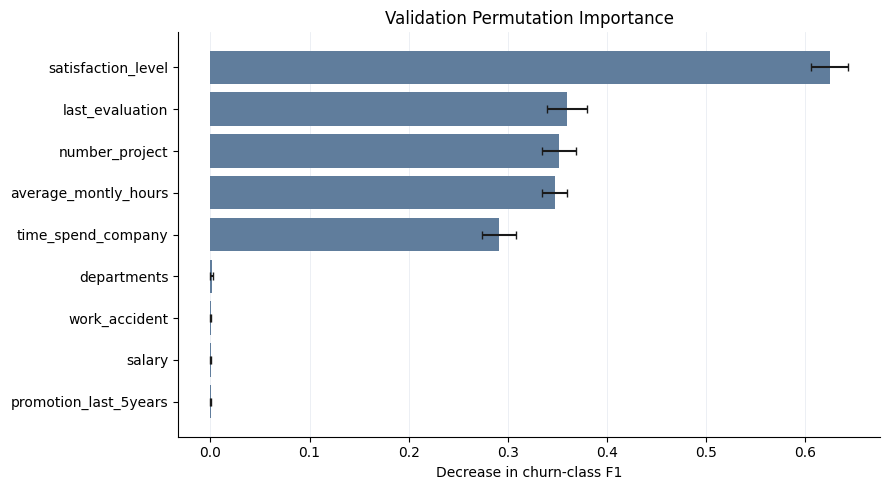

In [32]:
def threshold_f1(model, X, y):
    probabilities = model.predict_proba(X)[:, 1]
    predictions = (probabilities >= best_threshold).astype(int)
    return f1_score(y, predictions, zero_division=0)

importance = permutation_importance(
    best_model, X_val, y_val, scoring=threshold_f1,
    n_repeats=10, random_state=42,
)

importance_results = pd.DataFrame({
    'Feature': X_train.columns,
    'Mean F1 decrease': importance.importances_mean,
    'Std': importance.importances_std,
}).sort_values('Mean F1 decrease', ascending=False)
display(importance_results.round(4))

plot_data = importance_results.sort_values('Mean F1 decrease')
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(plot_data['Feature'], plot_data['Mean F1 decrease'],
        xerr=plot_data['Std'], color='#607D9C', capsize=3)
ax.set_title('Validation Permutation Importance')
ax.set_xlabel('Decrease in churn-class F1')
ax.set_axisbelow(True)
ax.grid(axis='x', color='#E9EDF2', linewidth=0.6)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

**Conclusion:** Satisfaction, last evaluation, and project count have the largest
importance scores. These connect to the satisfaction and workload patterns explored
in the EDA. Salary has little additional importance in this model, but this does
not mean salary is unrelated to churn or that any feature causes departures.

## 11. Final test evaluation
Compare all four CV-tuned models at threshold 0.5, plus an always-Stayed baseline.
Show the CV-selected model separately at its validation-selected threshold.
The selected model and settings stay fixed: test scores are for reporting, not selection.
The baseline shows why high accuracy alone can be misleading.

In [33]:
baseline = DummyClassifier(strategy='constant', constant=0)
baseline.fit(X_train, y_train)

# Compare each model's best CV configuration using the same threshold.
test_rows = []
for name, search in searches.items():
    probabilities = search.best_estimator_.predict_proba(X_test)[:, 1]
    row = {'Model': name, 'Decision rule': 'Default', 'Threshold': 0.5}
    row.update(evaluate_model(y_test, probabilities, 0.5))
    test_rows.append(row)

baseline_probabilities = baseline.predict_proba(X_test)[:, 1]
row = {'Model': 'Always Stayed', 'Decision rule': 'Baseline', 'Threshold': 0.5}
row.update(evaluate_model(y_test, baseline_probabilities, 0.5))
test_rows.append(row)

# Report the finalized model separately at its validation-selected threshold.
test_probabilities = best_model.predict_proba(X_test)[:, 1]
row = {'Model': best_name, 'Decision rule': 'Validation-selected', 'Threshold': best_threshold}
row.update(evaluate_model(y_test, test_probabilities, best_threshold))
test_rows.append(row)

test_results = pd.DataFrame(test_rows)
display(test_results.round(4))

# Save only the final results table. No model files or JSON metadata are written.
Path('results').mkdir(exist_ok=True)
test_results.to_csv('results/test_metrics.csv', index=False)

,Model,Decision rule,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,Average precision
0,Logistic Regression,Default,0.5000,0.7765,0.4130,0.8289,0.5513,0.8453,0.3843
1,KNN,Default,0.5000,0.9566,0.8374,0.9161,0.8750,0.9532,0.8531
2,Random Forest,Default,0.5000,0.9828,0.9785,0.9161,0.9463,0.9748,0.9611
3,Gradient Boosting,Default,0.5000,0.9844,0.9821,0.9228,0.9516,0.9753,0.9527
4,Always Stayed,Baseline,0.5000,0.8344,0.0000,0.0000,0.0000,0.5000,0.1656
5,Random Forest,Validation-selected,0.4983,0.9839,0.9786,0.9228,0.9499,0.9748,0.9611


**Final conclusion:** Random Forest achieves test F1 of 0.9499, precision of 0.9786,
and recall of 0.9228. The always-Stayed baseline achieves 83.4% accuracy but misses
every departure. Gradient Boosting has a slightly higher test F1 (0.9516), but
Random Forest remains selected because model selection used CV, not test scores.
Satisfaction and workload-related features are important for prediction.

## 12. Confusion matrix
Show the CV-selected model on the previously inspected test holdout using its
validation-selected threshold. Rows are recorded labels and columns are predictions.
Keep the model and threshold fixed; this is a final report, not further tuning.

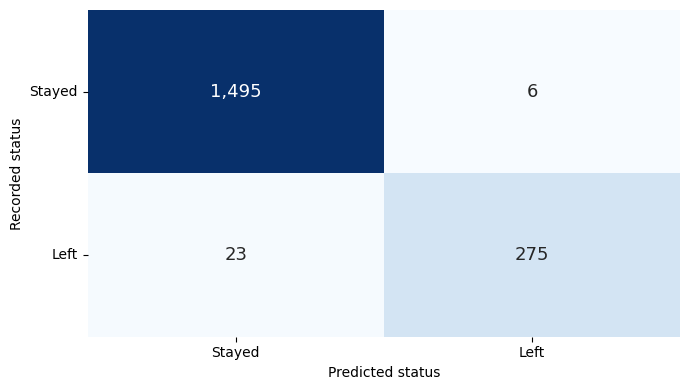

Model: Random Forest | Threshold: 0.4983
Correctly predicted Stayed: 1,495
Correctly predicted Left: 275
False positives: 6 stayed but were predicted Left.
False negatives: 23 left but were predicted Stayed.


In [34]:
selected_probabilities = best_model.predict_proba(X_test)[:, 1]
selected_predictions = (selected_probabilities >= best_threshold).astype(int)
matrix = confusion_matrix(y_test, selected_predictions, labels=[0, 1])

fig, ax = plt.subplots(figsize=(7, 4))
sns.heatmap(matrix, annot=True, fmt=',d', cmap='Blues', cbar=False,
            xticklabels=['Stayed', 'Left'], yticklabels=['Stayed', 'Left'],
            annot_kws={'size': 13}, ax=ax)
ax.set_xlabel('Predicted status')
ax.set_ylabel('Recorded status')
ax.tick_params(axis='y', labelrotation=0)
fig.tight_layout()
Path('plots').mkdir(exist_ok=True)
fig.savefig('plots/09_classification_confusion_matrix.png', dpi=300)
plt.show()

true_negatives, false_positives, false_negatives, true_positives = matrix.ravel()
print(f'Model: {best_name} | Threshold: {best_threshold:.4f}')
print(f'Correctly predicted Stayed: {true_negatives:,}')
print(f'Correctly predicted Left: {true_positives:,}')
print(f'False positives: {false_positives:,} stayed but were predicted Left.')
print(f'False negatives: {false_negatives:,} left but were predicted Stayed.')

## 13. ROC and precision–recall curves
Compare the four CV-tuned models on the previously inspected test holdout.
These curves use probability scores across thresholds, not just the selected threshold.
The ROC diagonal represents random ranking; the precision–recall reference line
is the test churn proportion. Test curves are for reporting, not further tuning.

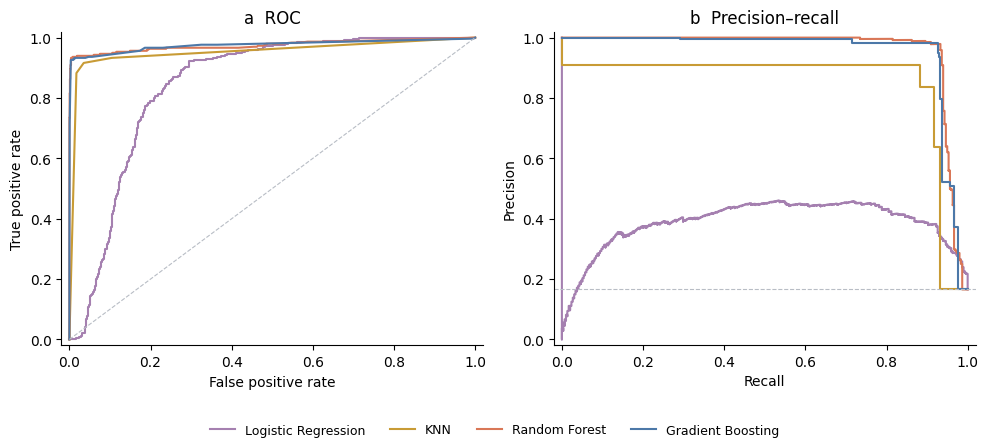

In [35]:
model_colors = {
    'Logistic Regression': '#A580B0',
    'KNN': '#C89B35',
    'Random Forest': '#D97757',
    'Gradient Boosting': '#4C78A8',
}

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for name, search in searches.items():
    probabilities = search.best_estimator_.predict_proba(X_test)[:, 1]
    false_positive_rate, true_positive_rate, _ = roc_curve(y_test, probabilities)
    precision, recall, _ = precision_recall_curve(y_test, probabilities)

    axes[0].plot(false_positive_rate, true_positive_rate,
                 label=name, color=model_colors[name], linewidth=1.5)
    axes[1].step(recall, precision, where='post',
                 label=name, color=model_colors[name], linewidth=1.5)

axes[0].plot([0, 1], [0, 1], color='#B8BDC5', linestyle='--', linewidth=0.8)
axes[1].axhline(y_test.mean(), color='#B8BDC5', linestyle='--', linewidth=0.8)
axes[0].set(title='a  ROC', xlabel='False positive rate', ylabel='True positive rate')
axes[1].set(title='b  Precision–recall', xlabel='Recall', ylabel='Precision')
for ax in axes:
    ax.set_xlim(-0.02, 1.02)
    ax.set_ylim(-0.02, 1.02)
    ax.spines[['top', 'right']].set_visible(False)

# One shared legend below the panels.
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.09, 1, 1))
Path('plots').mkdir(exist_ok=True)
fig.savefig('plots/08_classification_roc_pr.png', dpi=300)
plt.show()

**Key takeaway:** Curves closer to the upper-left corner of the ROC plot indicate
better discrimination. In the precision–recall plot, higher precision at a given
recall is better. Precision–recall curves are particularly useful here because
employees who left are the minority class. Random Forest remains the model
selected by training-set CV, regardless of the test-curve comparison.

## 14. Conclusion and saved outputs

Random Forest was selected by training-set CV, then its threshold was chosen
on validation data. The test comparison reports all four models without changing
that decision. These scores describe a previously inspected holdout, not
prospective performance. A future-departure model needs a prediction window and
confirmation that inputs were known before departure.

- **`plots/`**: seven EDA figures, the ROC/precision–recall comparison, and the confusion matrix.
- **`results/test_metrics.csv`**: all four models at 0.5, the always-Stayed baseline,
  and the selected model at its validation-selected threshold.
- **`best_model` and `best_threshold`**: available in memory for this kernel session only.

No `.pkl` files or split CSVs are written. Rerunning replaces the generated plots
and results table. The separate notebooks and `split_data.py` remain available
but are not required to run this notebook.